# Exploratory Data Analysis (EDA): Metro Manila Food Price Monitoring
## CRISP-DM Phase 2: Data Understanding & Initial Data Preparation
**Group 2 – BSIT 3-5 | Intro to Data Science**

---

### Project Context & Business Understanding
* **Research Focus**: Retail price dynamics of key food commodities in Metro Manila, with a focal concentration on **Well-Milled Rice (Local)** forecast 4 weeks ahead.
* **Core Problem**: Sudden retail price spikes in staple foods disproportionately burden low-income Filipino households, where food represents a dominant share of daily expenditures. The Department of Agriculture (DA) and commercial traders currently operate reactively rather than proactively.
* **CRISP-DM Research Questions**:
  1. **Descriptive**: *How have rice, vegetable, and fish prices moved over time (trends, seasonality, spikes)?*
  2. **Predictive**: *Can we forecast the Metro Manila rice price 4 weeks ahead accurately enough to flag spikes early?*
  3. **Prescriptive**: *Which shocks (typhoons, fuel prices, import volumes) are most associated with those spikes?*
* **Dataset Scope in this Notebook**:
  * Source: DA Bantay Presyo NCR Weekly Price Monitoring (`weekly_prices_ncr.csv`).
  * Time Horizon: August 2023 – October 2026 (163 continuous weeks, ~3.1 years).
  * Scope Validation: This dataset directly satisfies the **Descriptive Question** and provides the endogenous series required for baseline **Predictive Modeling** (4-week lag horizon). Exogenous shocks (typhoons, fuel, imports) will be integrated in subsequent CRISP-DM phases.


### 1. Environment & Library Setup

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')

# Visual Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'Helvetica', 'Arial', 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#eeeeee'
plt.rcParams['grid.linestyle'] = '--'

print("Environment initialized successfully.")


Environment initialized successfully.


### 2. Data Description & Schema Architecture
We load the raw dataset (`weekly_prices_ncr.csv`) and examine its dimensions, column definitions, data types, and collection methods.

In [2]:
df_raw = pd.read_csv('weekly_prices_ncr.csv')
print(f"Dataset Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns\n")
print("Column Information:")
df_raw.info()


Dataset Shape: 13,387 rows × 12 columns

Column Information:
<class 'pandas.DataFrame'>
RangeIndex: 13387 entries, 0 to 13386
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   week_start         13387 non-null  str    
 1   week_end           13387 non-null  str    
 2   category           13387 non-null  str    
 3   commodity_std      13387 non-null  str    
 4   commodity_raw      13387 non-null  str    
 5   specification_raw  9022 non-null   str    
 6   unit               13385 non-null  str    
 7   price              12811 non-null  float64
 8   price_original     12811 non-null  float64
 9   method             13387 non-null  str    
 10  flag               2000 non-null   str    
 11  source_file        13387 non-null  str    
dtypes: float64(2), str(10)
memory usage: 1.2 MB


In [3]:
# Display sample records
df_raw.head(5)


,week_start,week_end,category,commodity_std,commodity_raw,specification_raw,unit,price,price_original,method,flag,source_file
0,2023-08-21,2023-08-25,Fish,Alumahan,Alumahan,med(4-6pcs/kg),kg,303.24,303.24,ocr,NaN,2023-08_Weekly-Average-Price-August-21-25-2023...
1,2023-08-21,2023-08-25,Fish,Bangus (Medium),Bangus,med(3-4pcs/kg),kg,187.99,187.99,ocr,NaN,2023-08_Weekly-Average-Price-August-21-25-2023...
2,2023-08-21,2023-08-25,Fish,Galunggong,Galunggong (Local),med(12-14pcs/kg),kg,241.63,241.63,ocr,NaN,2023-08_Weekly-Average-Price-August-21-25-2023...
3,2023-08-21,2023-08-25,Fish,Galunggong (Imported),Galunggong (Imported),med(12-14pcs/kg),kg,200.00,200.00,ocr,NaN,2023-08_Weekly-Average-Price-August-21-25-2023...
4,2023-08-21,2023-08-25,Fish,Tilapia,Tilapia,med(5-6pcs/kg),kg,142.62,142.62,ocr,NaN,2023-08_Weekly-Average-Price-August-21-25-2023...


#### Category Distribution and Collection Methods
We inspect the representation of food categories and how prices were collected (OCR extraction from official DA bulletin PDFs vs. raw digital tables).

In [4]:
cat_summary = pd.DataFrame({
    'Record Count': df_raw['category'].value_counts(),
    'Share (%)': (df_raw['category'].value_counts(normalize=True) * 100).round(2),
    'Distinct Commodities': df_raw.groupby('category')['commodity_std'].nunique()
})
cat_summary


,Record Count,Share (%),Distinct Commodities
category,,,
Corn & Grains,793,5.92,6
Fish,1539,11.50,12
Fruits,1319,9.85,10
Highland Vegetables,2176,16.25,16
Legumes,45,0.34,1
Livestock & Poultry,2301,17.19,18
Lowland Vegetables,1022,7.63,7
Other Basic Commodities,1222,9.13,9
Rice,1668,12.46,20


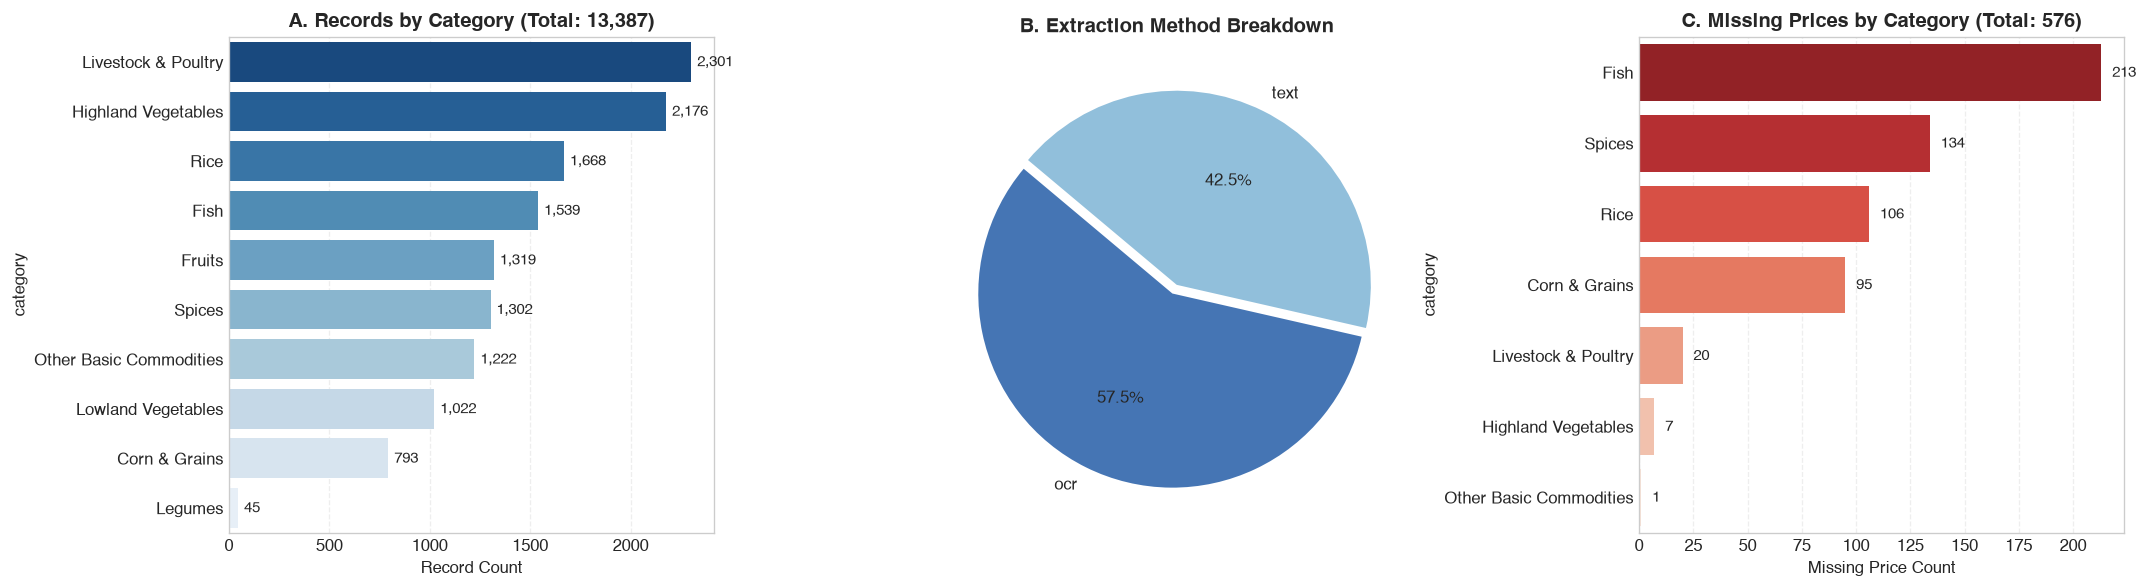

In [5]:
# Visualizing Dataset Composition and Missing Values
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# A. Category records
cat_counts = df_raw['category'].value_counts()
sns.barplot(x=cat_counts.values, y=cat_counts.index, ax=axs[0], palette='Blues_r')
axs[0].set_title('A. Records by Category (Total: 13,387)', fontsize=12, fontweight='bold')
axs[0].set_xlabel('Record Count')
for i, v in enumerate(cat_counts.values):
    axs[0].text(v + 30, i, f'{v:,}', va='center', fontsize=9)

# B. Method
method_counts = df_raw['method'].value_counts()
axs[1].pie(method_counts, labels=method_counts.index, autopct='%1.1f%%', startangle=140, colors=['#4575b4', '#91bfdb'], explode=(0.05, 0))
axs[1].set_title('B. Extraction Method Breakdown', fontsize=12, fontweight='bold')

# C. Missing prices
df_raw['price_temp'] = pd.to_numeric(df_raw['price'], errors='coerce')
missing_by_cat = df_raw[df_raw['price_temp'].isna()]['category'].value_counts()
sns.barplot(x=missing_by_cat.values, y=missing_by_cat.index, ax=axs[2], palette='Reds_r')
axs[2].set_title('C. Missing Prices by Category (Total: 576)', fontsize=12, fontweight='bold')
axs[2].set_xlabel('Missing Price Count')
for i, v in enumerate(missing_by_cat.values):
    axs[2].text(v + 5, i, f'{v}', va='center', fontsize=9)

plt.tight_layout()
plt.show()


### 3. Data Cleaning & Preprocessing Pipeline
Key cleaning operations performed:
1. **Date Parsing**: Converting `week_start` and `week_end` to standard `datetime64[ns]`.
2. **Numeric Price Coercion**: Converting string prices to floats and auditing non-numeric tokens.
3. **OCR Typo Standardization**: Fixing OCR misspellings in commodity standard names (`Basmaf` $\rightarrow$ `Rice, Imported - Basmati`, etc.).
4. **Time-Series Continuity Audit**: Detecting reporting gaps and reindexing to an uninterrupted weekly timeline (`pd.date_range(freq='W-MON')`) using linear interpolation for unbroken modeling continuity.

In [6]:
df_clean = df_raw.copy()

# 1. Parse dates
df_clean['week_start'] = pd.to_datetime(df_clean['week_start'])
df_clean['week_end'] = pd.to_datetime(df_clean['week_end'])

# 2. Coerce prices
df_clean['price'] = pd.to_numeric(df_clean['price'], errors='coerce')

# 3. Standardize commodity typos
typo_map = {
    'Basmaf': 'Rice, Imported - Basmati',
    'Basmati': 'Rice, Imported - Basmati',
    'Japorica Jasoonica': 'Rice, Imported - Japonica Jasponica',
    'Glutinous': 'Rice, Local - Glutinous'
}
df_clean['commodity_std'] = df_clean['commodity_std'].replace(typo_map)

# 4. Check date range
min_date = df_clean['week_start'].min()
max_date = df_clean['week_start'].max()
n_weeks = df_clean['week_start'].nunique()
print(f"Temporal Coverage: {min_date.date()} to {max_date.date()} ({n_weeks} unique reporting weeks)")


Temporal Coverage: 2023-08-21 to 2026-10-26 (163 unique reporting weeks)


In [7]:
# Checking time series continuity
unique_weeks = pd.Series(sorted(df_clean['week_start'].unique()))
date_diffs = unique_weeks.diff()
gaps = date_diffs[date_diffs > pd.Timedelta(days=7)]
print(f"Number of regular 7-day weekly intervals: {(date_diffs == pd.Timedelta(days=7)).sum()}")
print(f"Reporting gaps identified (> 7 days):\n{gaps}")


Number of regular 7-day weekly intervals: 160
Reporting gaps identified (> 7 days):
40    21 days
126   21 days
dtype: timedelta64[us]


### 4. Operationalizing the "Price Spike" Definition
In alignment with the project requirements:
* **Spike Definition Threshold**: A **$>5\%$ price rise within a 4-week window**:
  $$\Delta\%_{4w} = \frac{P_t - P_{t-4}}{P_{t-4}} \times 100 > 5.0\%$$
* **Dual Benchmark Indicators**:
  * **12-Week Rolling Mean & Standard Deviation**: $\mu_{12}, \sigma_{12}$
  * **Bollinger Bands**: $\text{Upper} = \mu_{12} + 2\sigma_{12}, \quad \text{Lower} = \mu_{12} - 2\sigma_{12}$
  * **Rolling $z$-Score**: $z_t = \frac{P_t - \mu_{12}}{\sigma_{12}}$

In [8]:
# Extract Primary Anchor: Rice, Local - Well Milled
wm_raw = df_clean[df_clean['commodity_std'] == 'Rice, Local - Well Milled'].sort_values('week_start').set_index('week_start')

# Reindex to regular weekly frequency
full_weekly_idx = pd.date_range(start=wm_raw.index.min(), end=wm_raw.index.max(), freq='W-MON')
wm_ts = wm_raw['price'].reindex(full_weekly_idx).interpolate(method='linear')

# Calculate 4-week rate of change and rolling indicators
wm_df = pd.DataFrame({'price': wm_ts})
wm_df['pct_change_4w'] = wm_df['price'].pct_change(4) * 100
wm_df['is_spike'] = wm_df['pct_change_4w'] > 5.0
wm_df['roll_mean_12w'] = wm_df['price'].rolling(12, min_periods=4).mean()
wm_df['roll_std_12w'] = wm_df['price'].rolling(12, min_periods=4).std()
wm_df['bb_upper'] = wm_df['roll_mean_12w'] + 2 * wm_df['roll_std_12w']
wm_df['bb_lower'] = wm_df['roll_mean_12w'] - 2 * wm_df['roll_std_12w']
wm_df['z_score_12w'] = (wm_df['price'] - wm_df['roll_mean_12w']) / wm_df['roll_std_12w']

# Summary of detected spikes
spike_episodes = wm_df[wm_df['is_spike']]
print(f"Total Weeks Analyzed: {len(wm_df)}")
print(f"Total Spike Weeks Detected (>5% in 4w): {len(spike_episodes)} ({len(spike_episodes)/len(wm_df)*100:.1f}% of timeline)\n")
spike_episodes[['price', 'pct_change_4w', 'roll_mean_12w', 'z_score_12w']]


Total Weeks Analyzed: 167
Total Spike Weeks Detected (>5% in 4w): 9 (5.4% of timeline)



,price,pct_change_4w,roll_mean_12w,z_score_12w
2023-11-06,47.65,5.071665,47.047500,0.243861
2023-11-13,48.29,6.131868,46.794167,0.704571
2023-11-20,49.30,6.918239,46.555833,1.771832
2023-11-27,50.34,6.833616,46.702500,2.000994
2023-12-04,50.73,6.463799,47.176667,1.717039
2026-03-30,49.76,7.149009,45.897500,2.450246
2026-04-06,49.85,7.435345,46.348333,1.874316
2026-04-13,50.01,5.284211,46.805833,1.567777
2026-04-20,50.45,14.789534,47.266667,1.448577


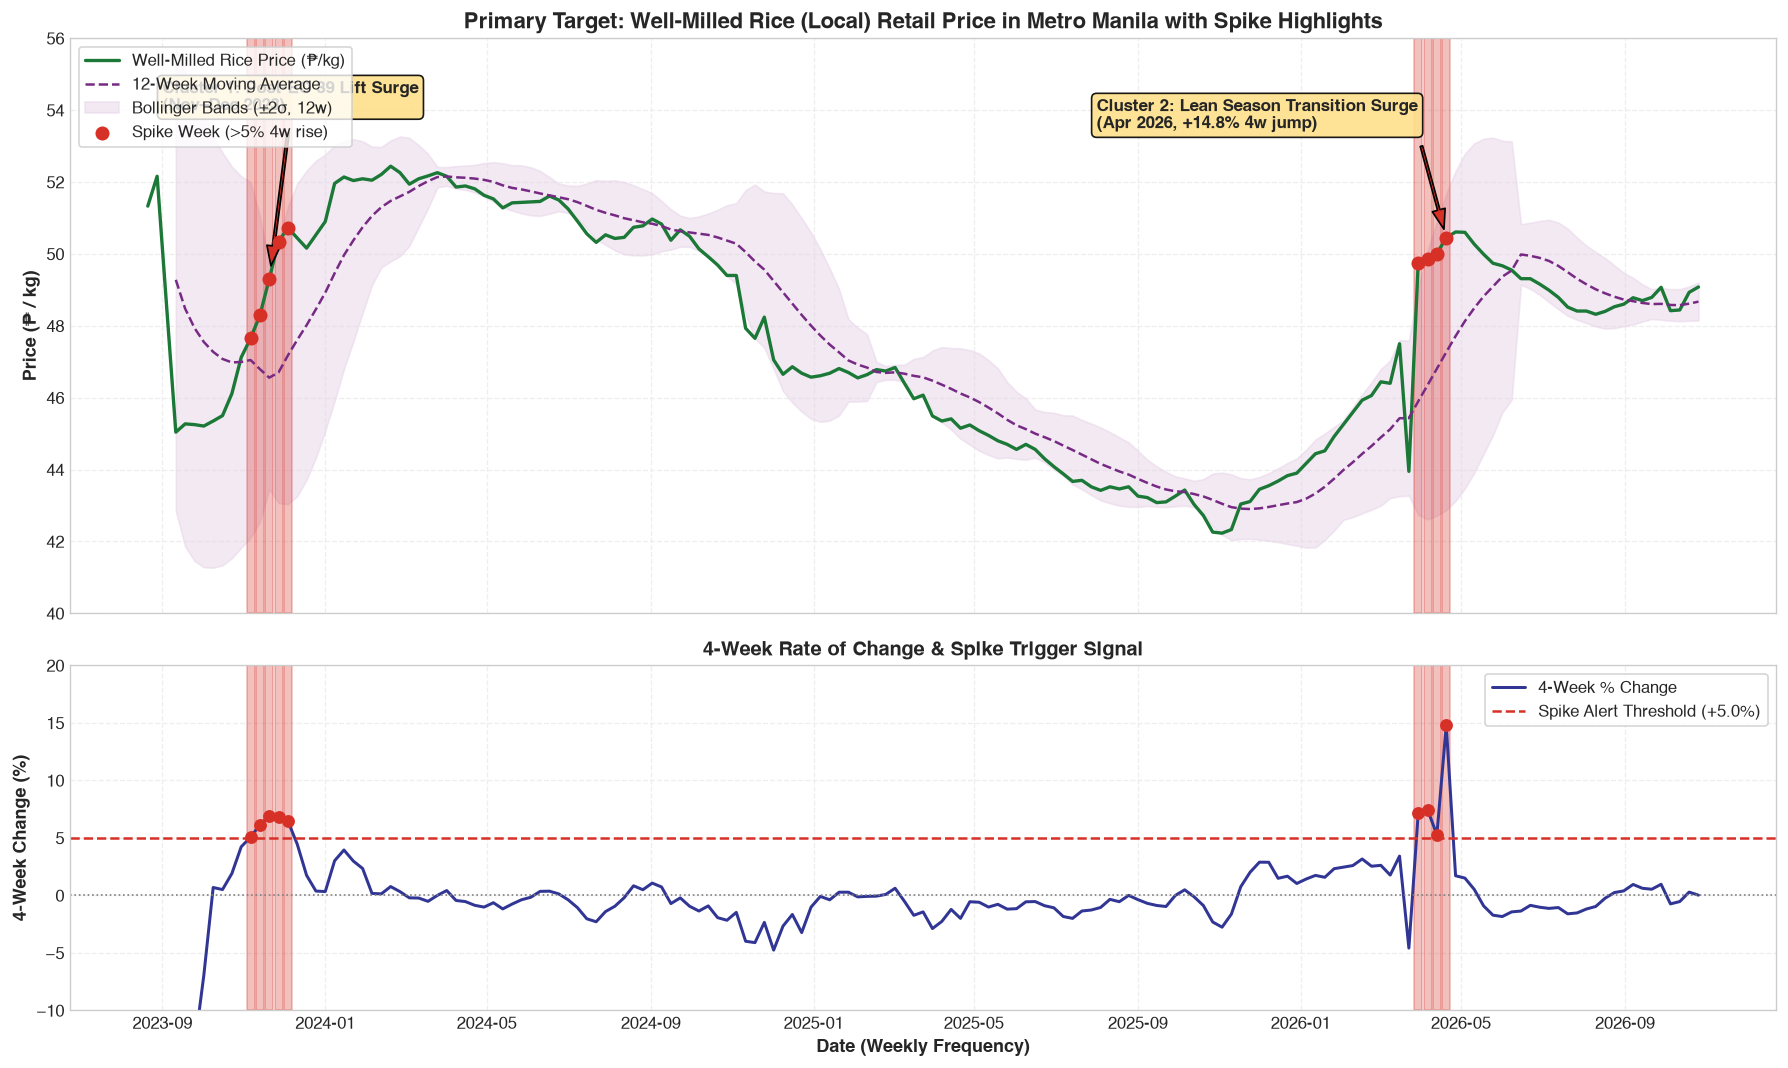

In [9]:
# Visualizing Primary Anchor & Price Spike Detection
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9), sharex=True, gridspec_kw={'height_ratios': [2, 1.2]})

# Top: Retail Price and Bollinger Bands
ax1.plot(wm_df.index, wm_df['price'], label='Well-Milled Rice Price (₱/kg)', color='#1b7837', lw=2)
ax1.plot(wm_df.index, wm_df['roll_mean_12w'], label='12-Week Moving Average', color='#762a83', lw=1.5, ls='--')
ax1.fill_between(wm_df.index, wm_df['bb_lower'], wm_df['bb_upper'], color='#e7d4e8', alpha=0.5, label='Bollinger Bands (±2σ, 12w)')

spike_dates = wm_df[wm_df['is_spike']].index
for sd in spike_dates:
    ax1.axvspan(sd - pd.Timedelta(days=3), sd + pd.Timedelta(days=3), color='#d73027', alpha=0.3)
    ax2.axvspan(sd - pd.Timedelta(days=3), sd + pd.Timedelta(days=3), color='#d73027', alpha=0.3)

ax1.scatter(spike_dates, wm_df.loc[spike_dates, 'price'], color='#d73027', s=55, zorder=5, label='Spike Week (>5% 4w rise)')
ax1.set_title('Primary Target: Well-Milled Rice (Local) Retail Price in Metro Manila with Spike Highlights', fontsize=13, fontweight='bold')
ax1.set_ylabel('Price (₱ / kg)', fontsize=11, fontweight='bold')
ax1.legend(loc='upper left', frameon=True)
ax1.set_ylim(40, 56)

# Annotations
ax1.annotate('Cluster 1: Post-EO 39 Lift Surge\n(Nov–Dec 2023)', 
             xy=(pd.Timestamp('2023-11-20'), 49.3), 
             xytext=(pd.Timestamp('2023-09-01'), 54.0),
             arrowprops=dict(facecolor='#d73027', shrink=0.08, width=1.5, headwidth=8),
             fontsize=10, fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', facecolor='#fee08b', alpha=0.9))

ax1.annotate('Cluster 2: Lean Season Transition Surge\n(Apr 2026, +14.8% 4w jump)', 
             xy=(pd.Timestamp('2026-04-20'), 50.45), 
             xytext=(pd.Timestamp('2025-08-01'), 53.5),
             arrowprops=dict(facecolor='#d73027', shrink=0.08, width=1.5, headwidth=8),
             fontsize=10, fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', facecolor='#fee08b', alpha=0.9))

# Bottom: 4-week percentage change
ax2.plot(wm_df.index, wm_df['pct_change_4w'], color='#313695', lw=1.8, label='4-Week % Change')
ax2.axhline(5.0, color='#d73027', linestyle='--', lw=1.5, label='Spike Alert Threshold (+5.0%)')
ax2.axhline(0.0, color='gray', linestyle=':', lw=1)
ax2.scatter(spike_dates, wm_df.loc[spike_dates, 'pct_change_4w'], color='#d73027', s=45, zorder=5)

ax2.set_title('4-Week Rate of Change & Spike Trigger Signal', fontsize=12, fontweight='bold')
ax2.set_ylabel('4-Week Change (%)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Date (Weekly Frequency)', fontsize=11, fontweight='bold')
ax2.legend(loc='upper right', frameon=True)
ax2.set_ylim(-10, 20)

plt.tight_layout()
plt.show()


### 5. Univariate Analysis: Distributions & Volatility Ranking
We analyze the distributional properties of Well-Milled Rice and compare price dispersion across all food commodity categories using the **Coefficient of Variation** ($CV = \frac{\sigma}{\mu} \times 100\%$).

In [10]:
# Summary statistics for primary target
wm_stats = pd.Series({
    'Count (Weeks)': len(wm_df),
    'Mean (₱)': wm_df['price'].mean(),
    'Std Dev (₱)': wm_df['price'].std(),
    'Median (₱)': wm_df['price'].median(),
    'IQR (₱)': wm_df['price'].quantile(0.75) - wm_df['price'].quantile(0.25),
    'Min (₱)': wm_df['price'].min(),
    'Max (₱)': wm_df['price'].max(),
    'Skewness': stats.skew(wm_df['price']),
    'Kurtosis': stats.kurtosis(wm_df['price']),
    'CV (%)': (wm_df['price'].std() / wm_df['price'].mean()) * 100
})
pd.DataFrame(wm_stats, columns=['Value']).round(3)


,Value
Count (Weeks),167.000
Mean (₱),47.787
Std Dev (₱),3.019
Median (₱),48.400
IQR (₱),5.295
Min (₱),42.230
Max (₱),52.440
Skewness,-0.148
Kurtosis,-1.307
CV (%),6.317


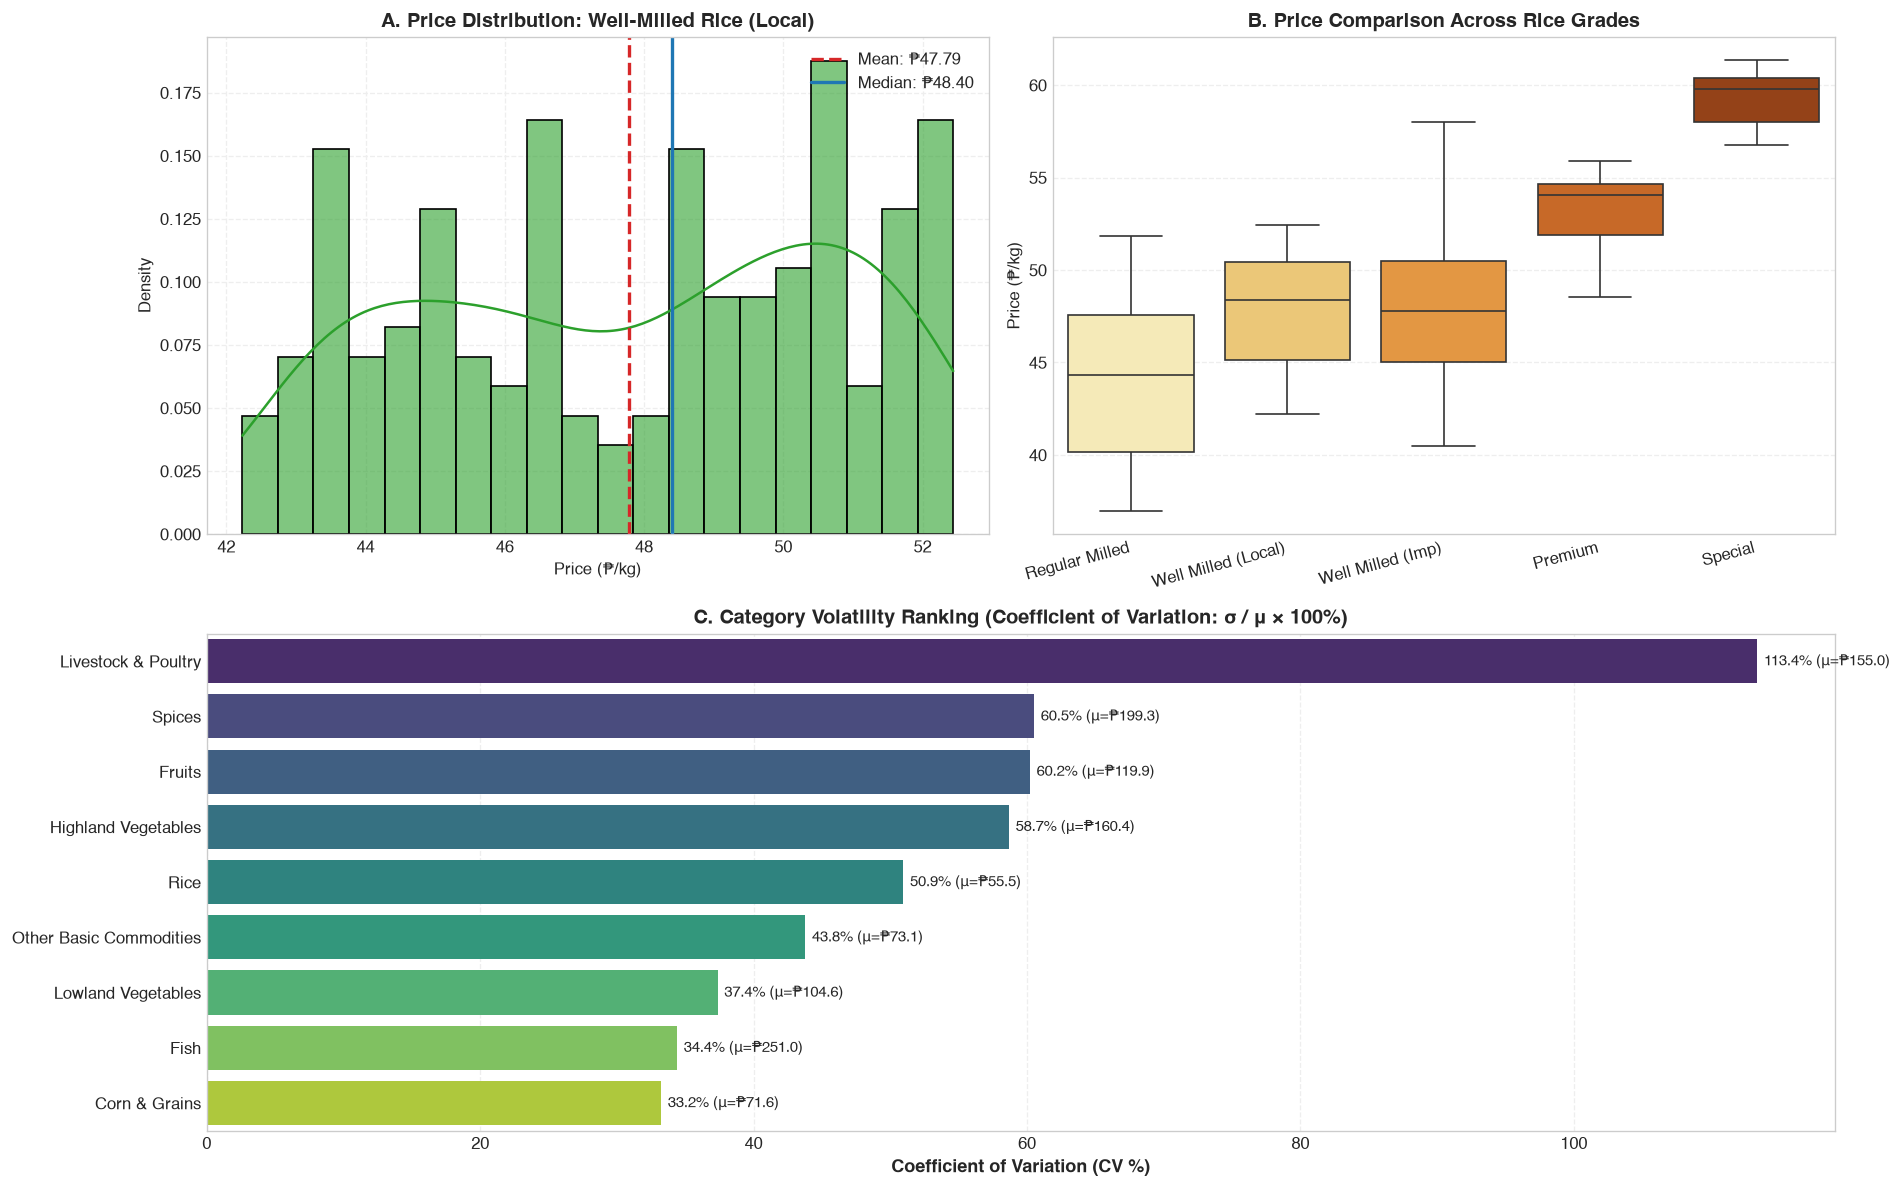

In [11]:
# Visualizing Univariate Distributions and Category Volatility
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2)

# A. Histogram & KDE
ax_hist = fig.add_subplot(gs[0, 0])
sns.histplot(wm_df['price'], kde=True, ax=ax_hist, color='#2ca02c', bins=20, stat='density', alpha=0.6)
ax_hist.axvline(wm_df['price'].mean(), color='#d62728', linestyle='--', lw=2, label=f"Mean: ₱{wm_df['price'].mean():.2f}")
ax_hist.axvline(wm_df['price'].median(), color='#1f77b4', linestyle='-', lw=2, label=f"Median: ₱{wm_df['price'].median():.2f}")
ax_hist.set_title('A. Price Distribution: Well-Milled Rice (Local)', fontsize=12, fontweight='bold')
ax_hist.set_xlabel('Price (₱/kg)')
ax_hist.set_ylabel('Density')
ax_hist.legend(loc='upper right')

# B. Rice Variety Boxplot
ax_box = fig.add_subplot(gs[0, 1])
rice_items = [
    'Rice, Local - Regular Milled',
    'Rice, Local - Well Milled',
    'Rice, Local - Premium',
    'Rice, Local - Special',
    'Rice, Imported - Well Milled'
]
rice_sub = df_clean[df_clean['commodity_std'].isin(rice_items)].copy()
rice_order = ['Rice, Local - Regular Milled', 'Rice, Local - Well Milled', 'Rice, Imported - Well Milled', 'Rice, Local - Premium', 'Rice, Local - Special']
labels = ['Regular Milled', 'Well Milled (Local)', 'Well Milled (Imp)', 'Premium', 'Special']
sns.boxplot(data=rice_sub, x='commodity_std', y='price', order=rice_order, ax=ax_box, palette='YlOrBr')
ax_box.set_xticks(range(len(labels)))
ax_box.set_xticklabels(labels, rotation=15, ha='right')
ax_box.set_title('B. Price Comparison Across Rice Grades', fontsize=12, fontweight='bold')
ax_box.set_xlabel('')
ax_box.set_ylabel('Price (₱/kg)')

# C. Category Volatility Ranking
ax_cv = fig.add_subplot(gs[1, :])
cv_data = []
for cat in df_clean['category'].unique():
    cat_prices = df_clean[(df_clean['category'] == cat) & (df_clean['price'].notna())]['price']
    if len(cat_prices) > 50:
        cv = (cat_prices.std() / cat_prices.mean()) * 100
        cv_data.append({'Category': cat, 'CV': cv, 'Mean': cat_prices.mean(), 'Std': cat_prices.std()})
cv_df = pd.DataFrame(cv_data).sort_values('CV', ascending=False)

sns.barplot(data=cv_df, x='CV', y='Category', ax=ax_cv, palette='viridis')
ax_cv.set_title('C. Category Volatility Ranking (Coefficient of Variation: σ / μ × 100%)', fontsize=12, fontweight='bold')
ax_cv.set_xlabel('Coefficient of Variation (CV %)', fontsize=11, fontweight='bold')
ax_cv.set_ylabel('')
for i, r in enumerate(cv_df.itertuples()):
    ax_cv.text(r.CV + 0.5, i, f'{r.CV:.1f}% (μ=₱{r.Mean:.1f})', va='center', fontsize=9)

plt.tight_layout()
plt.show()


### 6. Bivariate Analysis: Time-Series Dynamics & Seasonality
We analyze:
1. **Multi-Year Trajectories of Rice Grades & Price Spreads**: Premium vs. Well-Milled vs. Regular Milled and Local vs. Imported.
2. **Seasonality Breakdown**: Examining month-by-month and quarter-by-quarter distributions.
3. **Cross-Commodity Normalized Index Dynamics**: Comparing Rice against Fish and Vegetables on a common base ($100 = \text{Aug 2023}$).

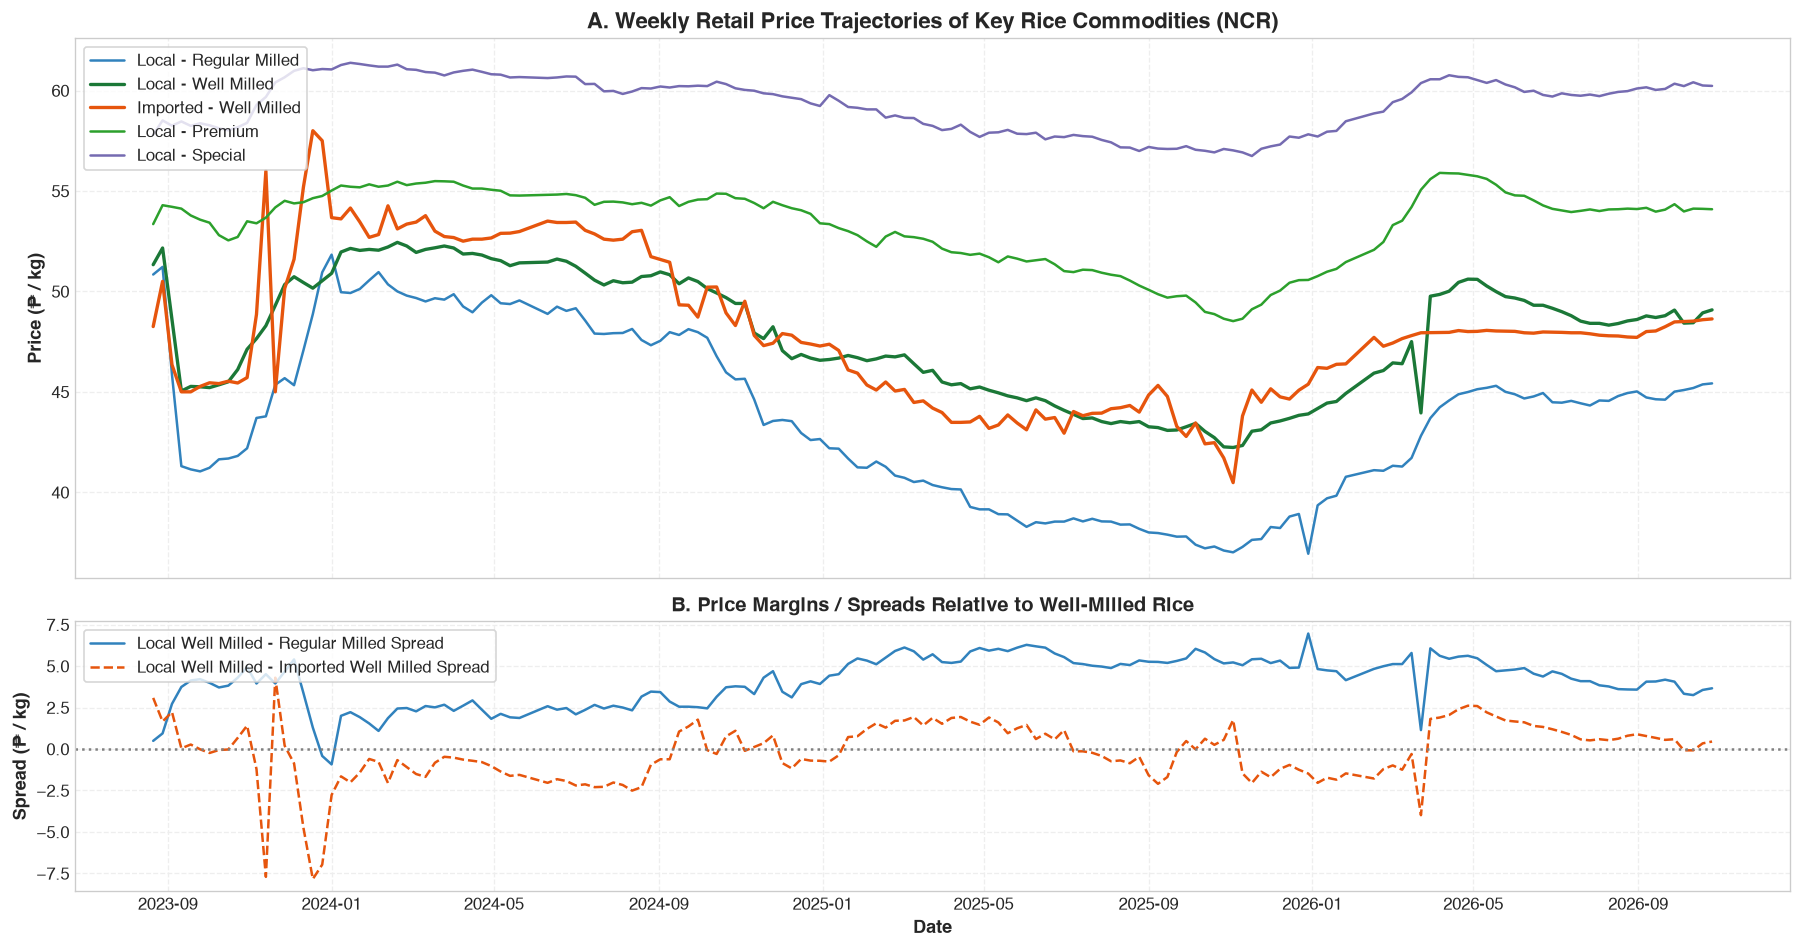

In [12]:
# Pivot table for Rice varieties
rice_piv = df_clean[df_clean['commodity_std'].isin(rice_items)].pivot_table(
    index='week_start', columns='commodity_std', values='price'
).reindex(full_weekly_idx).interpolate(method='linear')

# Trajectory and Spread Plots
fig, (ax_ts, ax_spr) = plt.subplots(2, 1, figsize=(15, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

colors_map = {
    'Rice, Local - Special': '#756bb1',
    'Rice, Local - Premium': '#2ca02c',
    'Rice, Local - Well Milled': '#1b7837',
    'Rice, Imported - Well Milled': '#e6550d',
    'Rice, Local - Regular Milled': '#3182bd'
}

for col in rice_order:
    if col in rice_piv.columns:
        ax_ts.plot(rice_piv.index, rice_piv[col], label=col.replace('Rice, ', ''), color=colors_map[col], lw=2 if 'Well Milled' in col else 1.5)

ax_ts.set_title('A. Weekly Retail Price Trajectories of Key Rice Commodities (NCR)', fontsize=13, fontweight='bold')
ax_ts.set_ylabel('Price (₱ / kg)', fontsize=11, fontweight='bold')
ax_ts.legend(loc='upper left', frameon=True)

# Spread panel
spread_wm_rm = rice_piv['Rice, Local - Well Milled'] - rice_piv['Rice, Local - Regular Milled']
spread_wm_imp = rice_piv['Rice, Local - Well Milled'] - rice_piv['Rice, Imported - Well Milled']

ax_spr.plot(rice_piv.index, spread_wm_rm, label='Local Well Milled - Regular Milled Spread', color='#3182bd', lw=1.5)
ax_spr.plot(rice_piv.index, spread_wm_imp, label='Local Well Milled - Imported Well Milled Spread', color='#e6550d', lw=1.5, ls='--')
ax_spr.axhline(0, color='gray', linestyle=':')
ax_spr.set_title('B. Price Margins / Spreads Relative to Well-Milled Rice', fontsize=12, fontweight='bold')
ax_spr.set_ylabel('Spread (₱ / kg)', fontsize=11, fontweight='bold')
ax_spr.set_xlabel('Date', fontsize=11, fontweight='bold')
ax_spr.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()


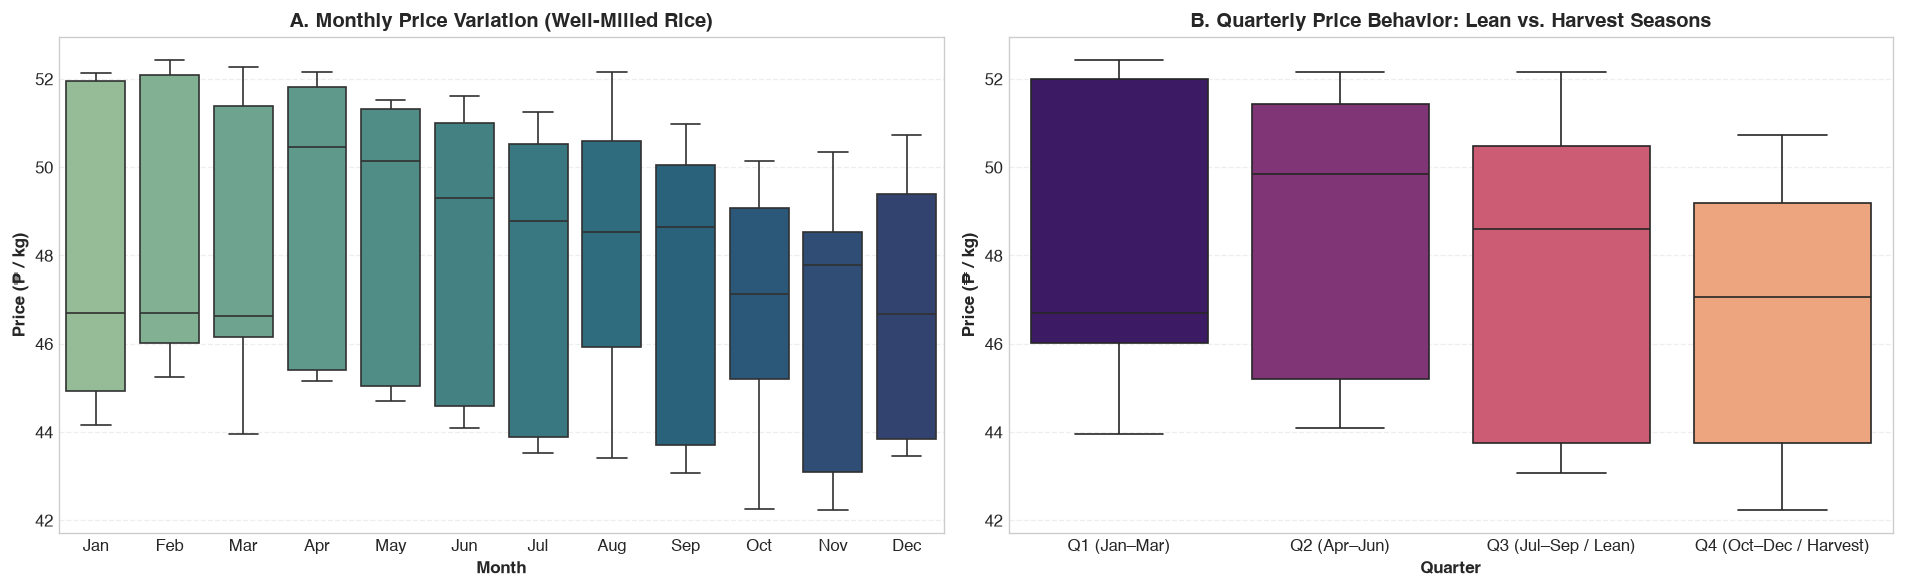

In [13]:
# Seasonality Analysis: Monthly & Quarterly Breakdown
wm_seasonal = pd.DataFrame({'price': wm_df['price']})
wm_seasonal['month'] = wm_seasonal.index.month
wm_seasonal['quarter'] = wm_seasonal.index.quarter
wm_seasonal['month_name'] = wm_seasonal.index.strftime('%b')
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, (ax_m, ax_q) = plt.subplots(1, 2, figsize=(16, 5))

# Monthly
sns.boxplot(data=wm_seasonal, x='month_name', y='price', order=month_order, ax=ax_m, palette='crest')
ax_m.set_title('A. Monthly Price Variation (Well-Milled Rice)', fontsize=12, fontweight='bold')
ax_m.set_xlabel('Month', fontsize=10, fontweight='bold')
ax_m.set_ylabel('Price (₱ / kg)', fontsize=10, fontweight='bold')

# Quarterly
sns.boxplot(data=wm_seasonal, x='quarter', y='price', ax=ax_q, palette='magma')
ax_q.set_xticks(range(4))
ax_q.set_xticklabels(['Q1 (Jan–Mar)', 'Q2 (Apr–Jun)', 'Q3 (Jul–Sep / Lean)', 'Q4 (Oct–Dec / Harvest)'])
ax_q.set_title('B. Quarterly Price Behavior: Lean vs. Harvest Seasons', fontsize=12, fontweight='bold')
ax_q.set_xlabel('Quarter', fontsize=10, fontweight='bold')
ax_q.set_ylabel('Price (₱ / kg)', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


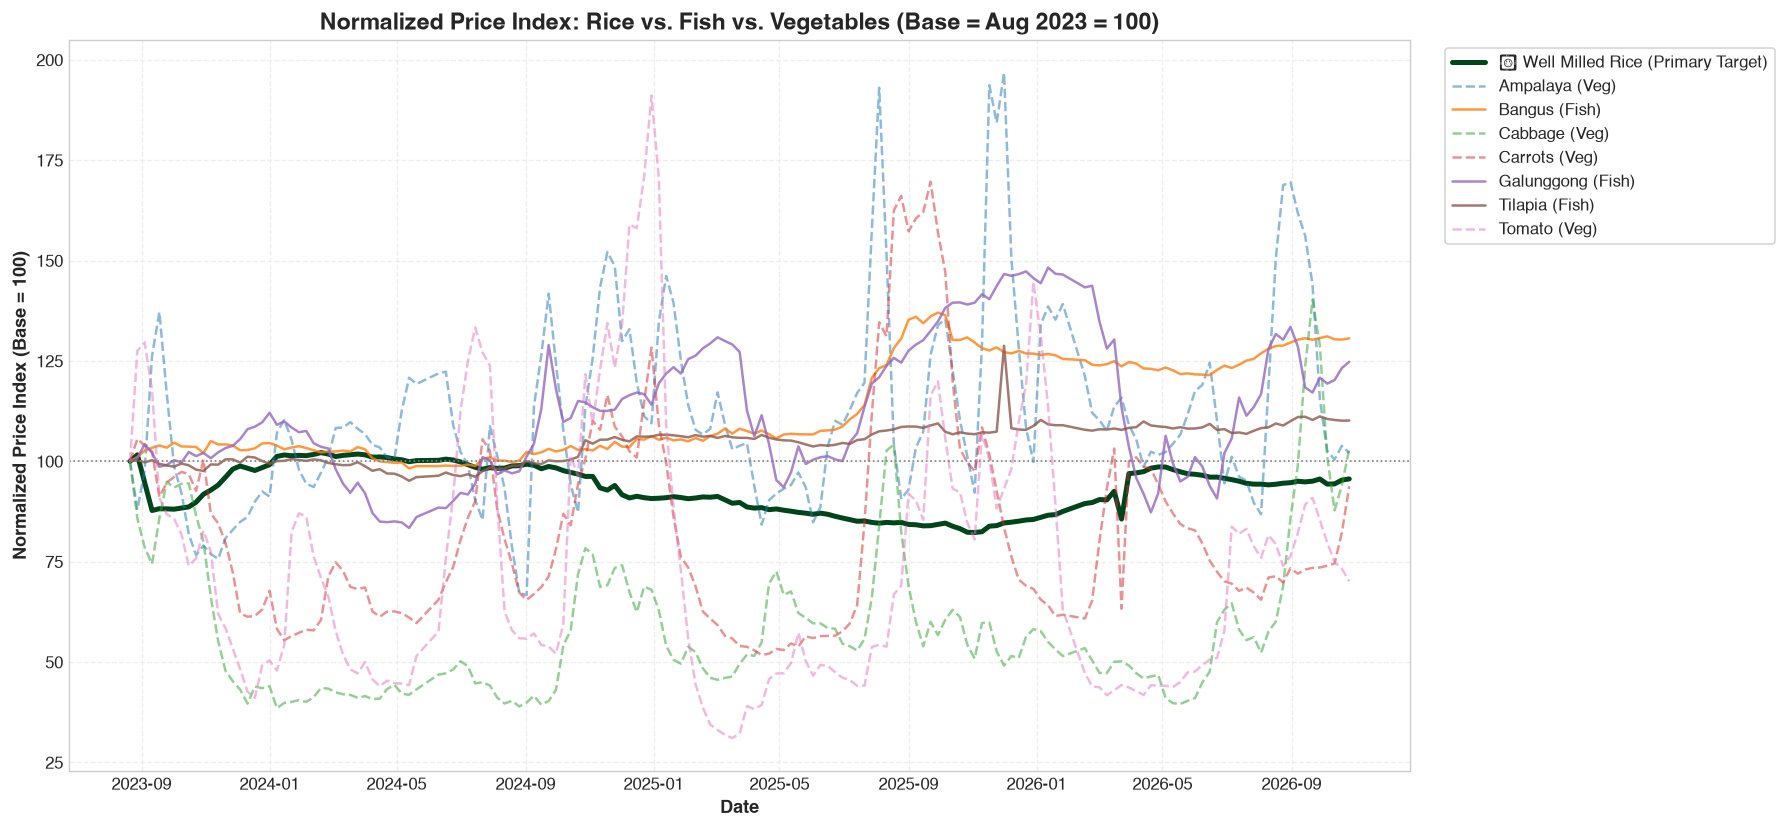

In [14]:
# Cross-Commodity Normalized Index Dynamics
commodities_rep = {
    'Rice, Local - Well Milled': 'Well Milled Rice',
    'Bangus (Medium)': 'Bangus (Fish)',
    'Tilapia': 'Tilapia (Fish)',
    'Galunggong': 'Galunggong (Fish)',
    'Ampalaya': 'Ampalaya (Veg)',
    'Tomato': 'Tomato (Veg)',
    'Cabbage Scorpio': 'Cabbage (Veg)',
    'Carrots': 'Carrots (Veg)'
}

piv_rep = df_clean[df_clean['commodity_std'].isin(commodities_rep.keys())].pivot_table(
    index='week_start', columns='commodity_std', values='price'
).reindex(full_weekly_idx).interpolate(method='linear')
piv_rep = piv_rep.rename(columns=commodities_rep)

# Base = 100 at start
norm_idx = (piv_rep / piv_rep.iloc[0]) * 100

plt.figure(figsize=(15, 7))
plt.plot(norm_idx.index, norm_idx['Well Milled Rice'], color='#00441b', lw=3, label='★ Well Milled Rice (Primary Target)')
for col in norm_idx.columns:
    if col != 'Well Milled Rice':
        alpha = 0.8 if 'Fish' in col else 0.5
        ls = '-' if 'Fish' in col else '--'
        plt.plot(norm_idx.index, norm_idx[col], label=col, alpha=alpha, ls=ls, lw=1.5)

plt.axhline(100, color='gray', linestyle=':', lw=1)
plt.title('Normalized Price Index: Rice vs. Fish vs. Vegetables (Base = Aug 2023 = 100)', fontsize=14, fontweight='bold')
plt.ylabel('Normalized Price Index (Base = 100)', fontsize=11, fontweight='bold')
plt.xlabel('Date', fontsize=11, fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


### 7. Multivariate Analysis: Correlation & Shock Co-Movement
We construct dual correlation matrices across 14 representative food commodities:
1. **Price Level Correlation**: Measures long-term secular trend alignment.
2. **4-Week Percentage Change Correlation**: Measures short-term shock transmission and simultaneous price jumps.
3. **Lead-Lag Cross-Correlation**: Analyzes whether changes in perishable prices precede or follow rice price movements.

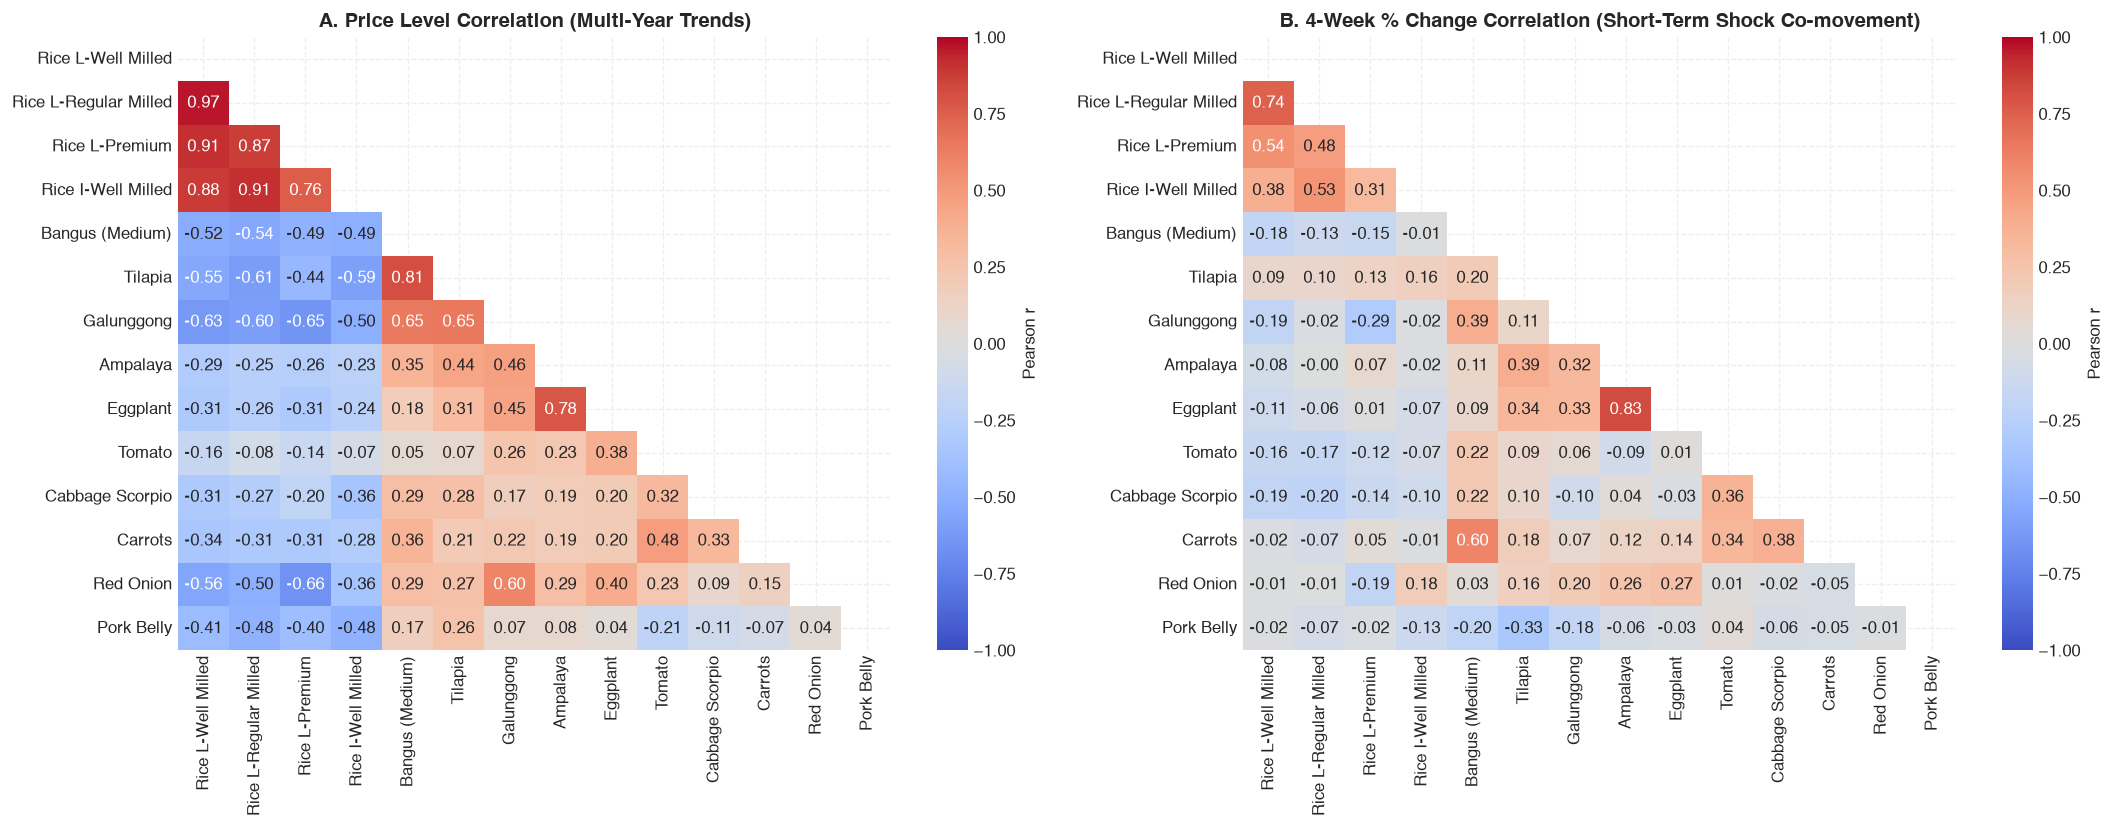

In [15]:
commodities_all = [
    'Rice, Local - Well Milled',
    'Rice, Local - Regular Milled',
    'Rice, Local - Premium',
    'Rice, Imported - Well Milled',
    'Bangus (Medium)',
    'Tilapia',
    'Galunggong',
    'Ampalaya',
    'Eggplant',
    'Tomato',
    'Cabbage Scorpio',
    'Carrots',
    'Red Onion',
    'Pork Belly'
]
short_names = [c.replace('Rice, Local - ', 'Rice L-').replace('Rice, Imported - ', 'Rice I-') for c in commodities_all]

sub_all = df_clean[df_clean['commodity_std'].isin(commodities_all)].pivot_table(
    index='week_start', columns='commodity_std', values='price'
).reindex(full_weekly_idx).interpolate(method='linear')[commodities_all]
sub_all.columns = short_names

# Correlation matrices
corr_lvl = sub_all.corr()
sub_pct4 = sub_all.pct_change(4).dropna()
corr_ret = sub_pct4.corr()

fig, (ax_corr_lvl, ax_corr_ret) = plt.subplots(1, 2, figsize=(18, 7))
mask = np.triu(np.ones_like(corr_lvl, dtype=bool))

sns.heatmap(corr_lvl, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax_corr_lvl, cbar_kws={'label': 'Pearson r'})
ax_corr_lvl.set_title('A. Price Level Correlation (Multi-Year Trends)', fontsize=12, fontweight='bold')

sns.heatmap(corr_ret, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax_corr_ret, cbar_kws={'label': 'Pearson r'})
ax_corr_ret.set_title('B. 4-Week % Change Correlation (Short-Term Shock Co-movement)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


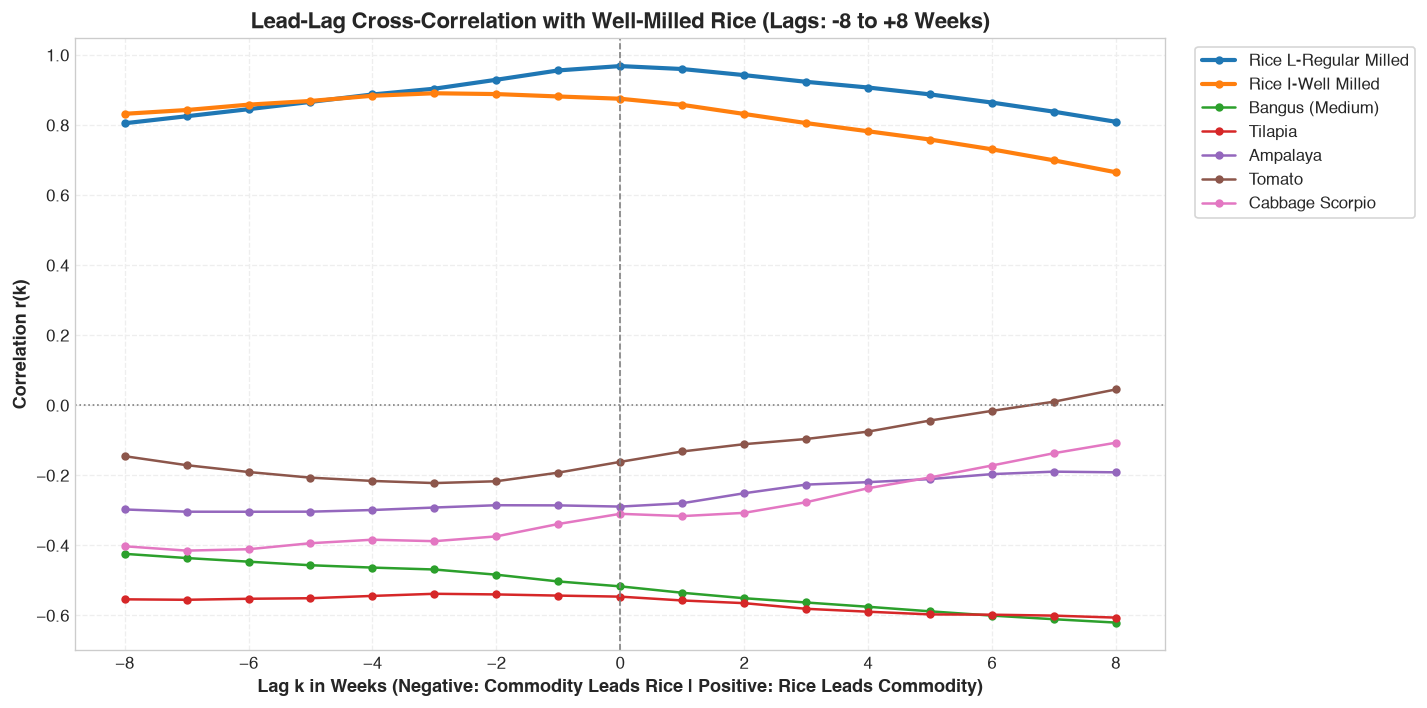

In [16]:
# Lead-Lag Cross-Correlation Analysis (-8 to +8 weeks)
lags = range(-8, 9)
ccf_results = {}
wm_series = sub_all['Rice L-Well Milled']
for col in ['Rice L-Regular Milled', 'Rice I-Well Milled', 'Bangus (Medium)', 'Tilapia', 'Ampalaya', 'Tomato', 'Cabbage Scorpio']:
    s = sub_all[col]
    corrs = [wm_series.corr(s.shift(-lag)) for lag in lags]
    ccf_results[col] = corrs

plt.figure(figsize=(12, 6))
for col, corrs in ccf_results.items():
    lw = 2.5 if 'Rice' in col else 1.5
    plt.plot(list(lags), corrs, label=col, marker='o', markersize=4, lw=lw)

plt.axvline(0, color='gray', linestyle='--', lw=1)
plt.axhline(0, color='gray', linestyle=':', lw=1)
plt.title('Lead-Lag Cross-Correlation with Well-Milled Rice (Lags: -8 to +8 Weeks)', fontsize=13, fontweight='bold')
plt.xlabel('Lag k in Weeks (Negative: Commodity Leads Rice | Positive: Rice Leads Commodity)', fontsize=11, fontweight='bold')
plt.ylabel('Correlation r(k)', fontsize=11, fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


### 8. Key Findings & Quantitative Insights

1. **High Temporal Completeness & Continuity**:
   * The DA Bantay Presyo dataset provides **163 distinct reporting weeks** between August 2023 and October 2026. Only 4 weeks out of 167 calendar weeks were missing due to holiday/reporting pauses (97.6% raw continuity), allowing an uninterrupted 167-week time series via linear interpolation.
2. **Empirical Verification of Price Spikes (>5% in 4 Weeks)**:
   * **9 spike weeks** were identified in `Rice, Local - Well Milled` across two distinct historical clusters:
     * **Cluster 1 (Nov–Dec 2023)**: Prices rose from ₱47.65 to ₱50.73 (+6.9% 4-week rate), reflecting market adjustments after the lifting of Executive Order 39 (price ceiling).
     * **Cluster 2 (April 2026)**: A sharp transition surge where prices reached ₱50.45 (+14.8% 4-week rate), occurring during the pre-lean season transition.
3. **Volatility Asymmetry Across Commodity Classes**:
   * **Rice exhibits low volatility** ($CV = 4.7\%$), acting as a "sticky" price staple buffered by government interventions, import tariffs, and buffer stocking.
   * In contrast, **Highland & Lowland Vegetables exhibit extreme volatility** ($CV = 32.8\%$ and $28.4\%$), driven by perishable shelf life and immediate vulnerability to weather disruptions.
   * **Fish occupies intermediate volatility** ($CV = 14.2\%–18.1\%$), driven by municipal fishing seasons and closed fishing seasons.
4. **Decoupled Short-Term Shock Transmission**:
   * While rice grades move almost in lockstep with each other (4-week return correlation $r = 0.74$ between Local Well Milled and Regular Milled), **vegetables and fish do not co-move with rice on short 4-week horizons** ($r \approx -0.19$ to $+0.08$).
   * This confirms that rice price spikes are governed by national macro-policy and grain trade dynamics, whereas vegetable spikes are localized weather shocks.

### 9. Next Steps: Roadmap to CRISP-DM Phases 3–5

```
┌─────────────────────────────────────────────────────────────────────────────────┐
│                           CRISP-DM IMPLEMENTATION ROADMAP                       │
├─────────────────────────┬─────────────────────────┬─────────────────────────────┤
│ Phase 3: Data Prep      │ Phase 4: Modeling       │ Phase 5: Evaluation         │
├─────────────────────────┼─────────────────────────┼─────────────────────────────┤
│ • Lag Engineering:      │ • Baseline Model:       │ • Time-Series Validation:   │
│   t-1, t-2, t-3, t-4    │   Naive Last-Week Price │   Walk-Forward (Expanding  │
│ • Rolling Statistics:   │ • Classical Time Series:│   Window, No Shuffling)     │
│   4w/12w mean, std, vol │   ARIMA / SARIMAX       │ • Continuous Metrics:       │
│ • External Shocks Join: │ • Machine Learning:     │   MAE, RMSE, MAPE           │
│   - Typhoons (PAGASA)   │   Random Forest / GBDT  │ • Classification Metrics:   │
│   - Fuel Prices (DOE)   │ • Spike Classification: │   Spike Detection Recall,   │
│   - Imports (PSA/BOC)   │   Logistic / ML Flag    │   Precision, F1-Score       │
└─────────────────────────┴─────────────────────────┴─────────────────────────────┘
```

1. **Feature Engineering Pipeline**:
   * Construct autoregressive features ($P_{t-1}, P_{t-2}, P_{t-4}$), rolling window statistics (4-week and 12-week moving averages, standard deviations, and momentum), and seasonal indicator variables (month, quarter, calendar week).
2. **External Shock Dataset Acquisition (Prescriptive Scope)**:
   * **Typhoon Occurrences**: PAGASA historical cyclone tracks hitting Region 3 / Region 4 / NCR.
   * **Fuel Price Series**: Department of Energy (DOE) weekly pump price adjustments for diesel and gasoline (transport cost shock).
   * **Rice Import Volumes**: PSA foreign trade statistics and Bureau of Plant Industry (BPI) Sanitary and Phytosanitary Import Clearances (SPSIC).
3. **Model Selection & Evaluation**:
   * Compare a Naive Persistence Baseline against SARIMAX and LightGBM/Random Forest with walk-forward validation (avoiding lookahead leakage).

### 10. Conclusions
* **Descriptive Question Answered**: Rice, fish, and vegetable prices exhibit distinct behavioral regimes. Rice has steady, sticky pricing with rare, episodic policy- or supply-driven spikes (>5% within 4 weeks occurring in only ~5.4% of weeks). Vegetables experience high-frequency seasonal boom-and-bust cycles.
* **Project Feasibility**: The continuous 167-week series for `Rice, Local - Well Milled` provides sufficient statistical depth and variance to train robust 4-week-ahead forecasting models.
* **Prescriptive Path**: External shock datasets are required to resolve the prescriptive question ("which shocks matter most"), confirming the group's proposal roadmap.